<a href="https://colab.research.google.com/github/iagopbn-ai/DataScience_MKT/blob/main/Projeto_Airbnb_Rio_CRISP_DM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Airbnb no Rio de Janeiro: pequenos anfitriões conseguem competir?

**Projeto aplicado — Marketing Digital / Ciência de Dados (CEUB) · Metodologia CRISP-DM**

Este notebook consolida o **Anfitrião Carioca** com a análise de competitividade de pequenos anfitriões. A proposta é identificar características que favorecem atratividade, confiança e potencial de reservas, sem confundir indicadores de oferta com conversão comprovada.

**Fonte:** Inside Airbnb, arquivo `listings.csv.gz` (*Detailed Listings data*) do Rio de Janeiro. Também aceita `listings.csv`.

No Google Colab, faça upload do CSV e execute as células na ordem. Os gráficos e tabelas gerados podem ser usados como evidências no relatório e nas capturas de tela.

## 1. Compreensão do negócio

### Pergunta central

Pequenos anfitriões conseguem competir com anúncios mais estruturados no Rio de Janeiro? Quais variáveis devem ser priorizadas para melhorar posicionamento, preço, confiança e disponibilidade?

### Objetivos

- Comparar pequenos e grandes anfitriões por preço, nota, reviews e disponibilidade.
- Identificar gargalos da oferta por bairro e tipo de acomodação.
- Produzir recomendações para campanhas de tráfego pago e melhoria do anúncio.
- Indicar hipóteses que ainda precisam de dados de cliques, reservas e receita.

In [1]:
import io
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')

DATA_PATH = 'listings.csv'
try:
    df = pd.read_csv(DATA_PATH, low_memory=False)
except FileNotFoundError:
    from google.colab import files
    uploaded = files.upload()
    name = next(n for n in uploaded if n.lower().endswith(('.csv', '.csv.gz')))
    df = pd.read_csv(io.BytesIO(uploaded[name]), low_memory=False)

print(f'{df.shape[0]:,} linhas e {df.shape[1]} colunas')
display(df.head(3))

Saving listings.csv to listings.csv
48,247 linhas e 90 colunas


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,17878,https://www.airbnb.com/rooms/17878,20260922161726,2026-09-27,NaN,"Very Nice 2Br in Copacabana w. balcony, fast WiFi",Please note that elevated rates apply for New ...,NaN,https://a0.muscache.com/pictures/65320518/3069...,68997,https://www.airbnb.com/users/show/68997,1462508300544974201,https://www.airbnb.com/users/profile/146250830...,Matthias,NaN,16.0,8.0,15.0,8.0,"Rio de Janeiro, Brazil",I am a journalist/writer. Lived in NYC for ...,NaN,NaN,NaN,t,NaN,https://a0.muscache.com/im/pictures/user/67b13...,NaN,2,NaN,NaN,t,t,NaN,Copacabana,NaN,-22.96599,-43.17940,Entire condo,Entire home/apt,5,NaN,1 bath,2.0,2.0,"[""Dining table"", ""Dako stainless steel gas sto...",$513.00,2026-09-30,2026-10-04,2052.0,513.0,"{""quote"": {""taxes"": null, ""currency"": ""BRL"", ""...",1.0,28.0,1.0,4.0,28.0,28.0,4.0,28.0,NaN,t,19,25,34,194,2026-09-27,359,18,2,39,21,108,55404.0,2010-07-15,2026-09-13,4.72,4.77,4.65,4.84,4.91,4.78,4.68,NaN,NaN,1,1,0,0,1.82
1,25026,https://www.airbnb.com/rooms/25026,20260922161726,2026-09-27,NaN,Beautiful Modern Decorated Studio in Copacabana,"Our apartment is a little gem, everyone loves ...",NaN,https://a0.muscache.com/pictures/7c08fa4f-1d7b...,102840,https://www.airbnb.com/users/show/102840,1462509657143978873,https://www.airbnb.com/users/profile/146250965...,Viviane,NaN,16.0,5.0,15.0,8.0,"Rio de Janeiro, Brazil","Olá! I’m Viviane, born and raised in Rio de Ja...",NaN,NaN,NaN,t,NaN,https://a0.muscache.com/im/pictures/user/315dd...,NaN,1,NaN,NaN,t,t,NaN,Copacabana,NaN,-22.97649,-43.19122,Entire rental unit,Entire home/apt,3,NaN,1 bath,1.0,2.0,"[""Dining table"", ""Coffee"", ""Paid street parkin...",$422.00,2026-09-27,2026-09-29,844.0,422.0,"{""quote"": {""taxes"": null, ""currency"": ""BRL"", ""...",2.0,60.0,2.0,2.0,30.0,60.0,2.0,56.1,NaN,t,25,42,66,200,2026-09-27,333,20,3,66,15,120,50640.0,2010-06-07,2026-09-20,4.77,4.75,4.82,4.84,4.94,4.86,4.66,NaN,NaN,1,1,0,0,1.68
2,35764,https://www.airbnb.com/rooms/35764,20260922161726,2026-09-27,NaN,COPACABANA SEA BREEZE - RIO - 25 X Superhost,Our newly renovated studio is located in the b...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,153691,https://www.airbnb.com/users/show/153691,1462511105909784454,https://www.airbnb.com/users/profile/146251110...,Patricia&Paulo,NaN,16.0,2.0,15.0,8.0,"Rio de Janeiro, Brazil","Hello, We are

## 2. Compreensão e qualidade dos dados

In [2]:
profile = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'nulos': df.isna().sum(),
    '% nulos': (df.isna().mean() * 100).round(2),
    'unicos': df.nunique()
}).sort_values('% nulos', ascending=False)
display(profile.head(25))
if 'id' in df.columns:
    print('Duplicatas por id:', df.duplicated('id').sum())
else:
    print('Duplicatas de linhas:', df.duplicated().sum())

,tipo,nulos,% nulos,unicos
neighborhood_overview,float64,48247,100.00,0
host_since,float64,48247,100.00,0
host_response_time,float64,48247,100.00,0
host_thumbnail_url,float64,48247,100.00,0
host_acceptance_rate,float64,48247,100.00,0
host_response_rate,float64,48247,100.00,0
host_verifications,float64,48247,100.00,0
neighbourhood,float64,48247,100.00,0
host_total_listings_count,float64,48247,100.00,0
host_neighbourhood,float64,48247,100.00,0


Duplicatas por id: 0


## 3. Preparação dos dados

In [3]:
analysis = df.copy()

def to_money(value):
    if pd.isna(value):
        return np.nan
    text = re.sub(r'[^0-9,.-]', '', str(value))
    if not text:
        return np.nan
    if ',' in text and '.' in text:
        text = text.replace('.', '').replace(',', '.')
    elif ',' in text:
        text = text.replace(',', '.')
    try:
        return float(text)
    except ValueError:
        return np.nan

if 'price' in analysis.columns:
    analysis['price_brl'] = analysis['price'].map(to_money)
if {'price_brl', 'accommodates'}.issubset(analysis.columns):
    analysis['price_per_guest'] = analysis['price_brl'] / analysis['accommodates'].replace(0, np.nan)
if 'price_brl' in analysis.columns:
    analysis.loc[analysis['price_brl'] <= 0, 'price_brl'] = np.nan
if 'review_scores_rating' in analysis.columns:
    analysis.loc[~analysis['review_scores_rating'].between(0, 5), 'review_scores_rating'] = np.nan
print('Preço mediano: R$', round(analysis['price_brl'].median(), 2) if 'price_brl' in analysis else 'indisponível')
display(analysis.describe(include='all').T.head(20))

Preço mediano: R$ 349.3


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,48247.0,NaN,NaN,NaN,1053310614595305472.0,625000140750777984.0,17878.0,697441502987602560.0,1284205028578335232.0,1575006356142987520.0,1780042005461358592.0
listing_url,48247,48247,https://www.airbnb.com/rooms/17878,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
scrape_id,48247.0,NaN,NaN,NaN,20260922161726.0,24.297127,20260922161726.0,20260922161726.0,20260922161726.0,20260922161726.0,20260922161726.0
last_scraped,48247,7,2026-09-27,12610,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source,4811,1,previous scrape,4811,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,48247,46226,Apartamento em Copacabana,127,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,48024,43330,Relax with the whole family at this peaceful p...,275,NaN,NaN,NaN,NaN,NaN,NaN,NaN
neighborhood_overview,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
picture_url,48247,47382,https://a0.muscache.com/pictures/dc1b2280-007c...,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
host_id,48247.0,NaN,NaN,NaN,31188457588779816.0,229539054451136512.0,3607.0,47584281.0,203022450.0,483358602.0,1782050693278006272.0


## 4. Análise exploratória dos gargalos

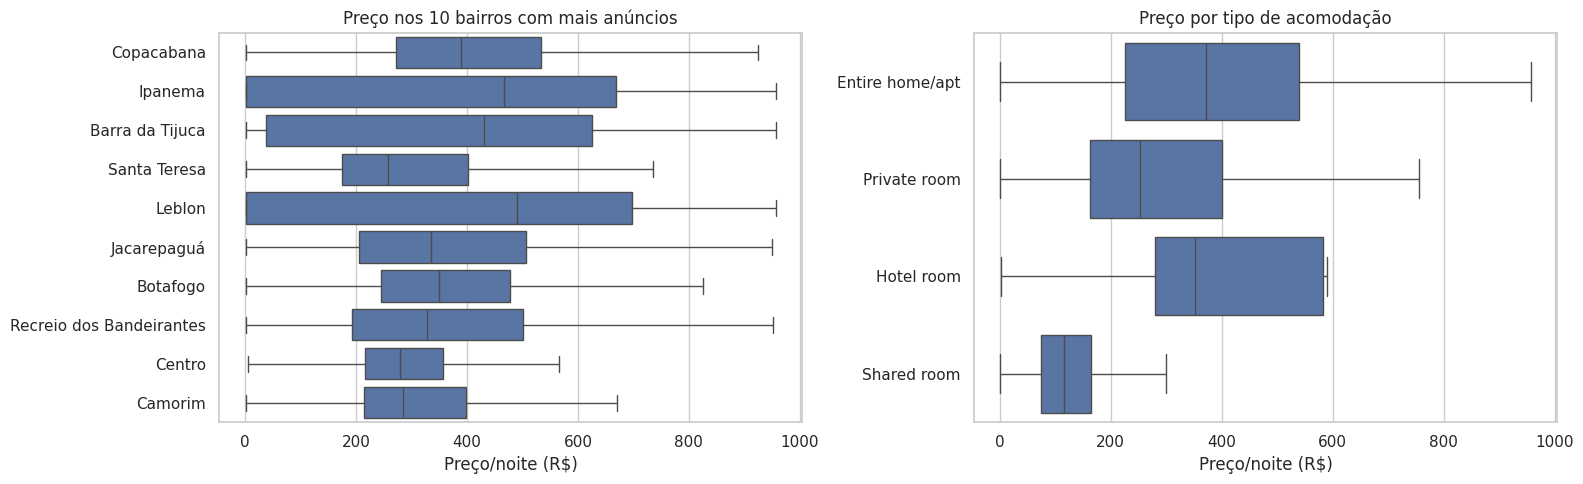

In [4]:
plot_df = analysis.copy()
if 'price_brl' in plot_df.columns:
    q1, q99 = plot_df['price_brl'].quantile([0.01, 0.99])
    plot_df = plot_df[plot_df['price_brl'].between(q1, q99)]
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
if {'neighbourhood_cleansed', 'price_brl'}.issubset(plot_df.columns):
    top = plot_df['neighbourhood_cleansed'].value_counts().head(10).index
    sns.boxplot(data=plot_df[plot_df['neighbourhood_cleansed'].isin(top)], x='price_brl', y='neighbourhood_cleansed', showfliers=False, ax=ax[0])
    ax[0].set_title('Preço nos 10 bairros com mais anúncios'); ax[0].set_xlabel('Preço/noite (R$)'); ax[0].set_ylabel('')
if {'room_type', 'price_brl'}.issubset(plot_df.columns):
    sns.boxplot(data=plot_df, x='price_brl', y='room_type', showfliers=False, ax=ax[1])
    ax[1].set_title('Preço por tipo de acomodação'); ax[1].set_xlabel('Preço/noite (R$)'); ax[1].set_ylabel('')
plt.tight_layout(); plt.show()

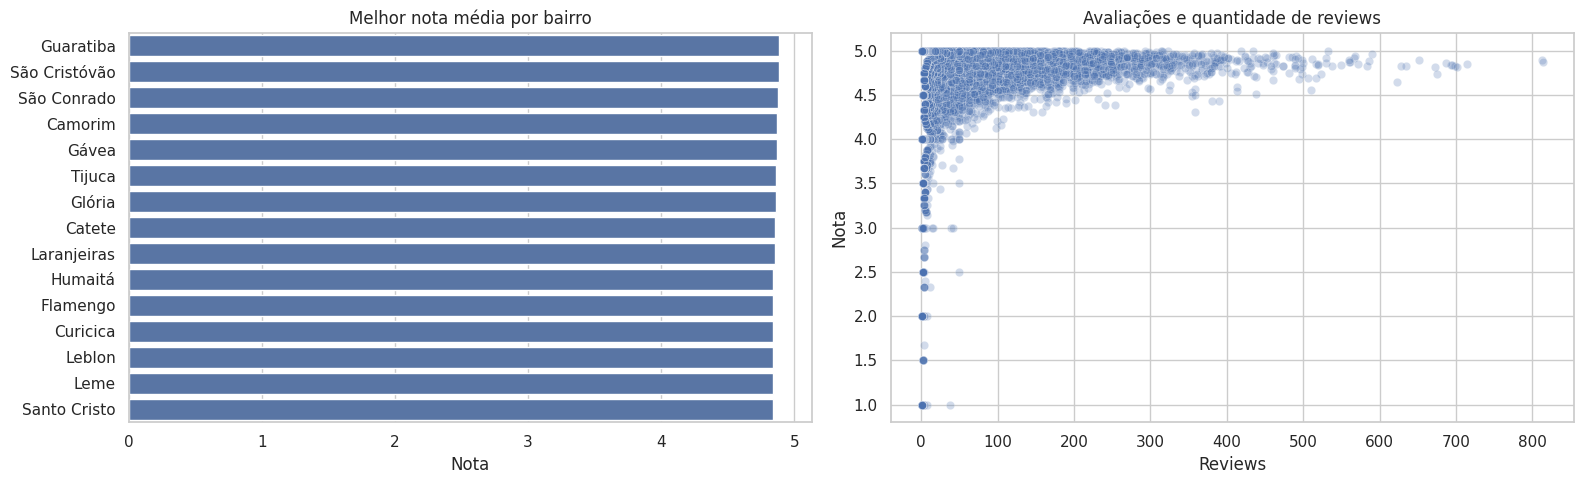

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
if {'neighbourhood_cleansed', 'review_scores_rating', 'id'}.issubset(analysis.columns):
    ratings = (analysis.groupby('neighbourhood_cleansed').agg(anuncios=('id', 'count'), nota=('review_scores_rating', 'mean')).query('anuncios >= 100').sort_values('nota', ascending=False).head(15).reset_index())
    sns.barplot(data=ratings, y='neighbourhood_cleansed', x='nota', ax=ax[0]); ax[0].set_title('Melhor nota média por bairro'); ax[0].set_xlabel('Nota'); ax[0].set_ylabel('')
if {'number_of_reviews', 'review_scores_rating'}.issubset(analysis.columns):
    sns.scatterplot(data=analysis, x='number_of_reviews', y='review_scores_rating', alpha=.25, ax=ax[1]); ax[1].set_title('Avaliações e quantidade de reviews'); ax[1].set_xlabel('Reviews'); ax[1].set_ylabel('Nota')
plt.tight_layout(); plt.show()

## 5. Competitividade dos pequenos anfitriões

Usamos `calculated_host_listings_count` como proxy de porte: pequenos anfitriões têm até 2 anúncios; os demais formam o grupo de comparação. Essa é uma hipótese operacional e pode ser ajustada se houver outra definição no projeto.

In [6]:
if 'calculated_host_listings_count' in analysis.columns:
    analysis['porte_anfitriao'] = np.where(analysis['calculated_host_listings_count'] <= 2, 'Pequeno (1–2 anúncios)', 'Maior (3+ anúncios)')
    metrics = [c for c in ['price_brl', 'review_scores_rating', 'number_of_reviews', 'availability_365', 'reviews_per_month'] if c in analysis.columns]
    comparison = analysis.groupby('porte_anfitriao')[metrics].median().round(2)
    print('Comparação por porte do anfitrião — medianas')
    display(comparison)
    if {'neighbourhood_cleansed', 'id'}.issubset(analysis.columns):
        by_neighbourhood = (analysis.groupby(['neighbourhood_cleansed', 'porte_anfitriao']).agg(anuncios=('id', 'count'), preco_mediano=('price_brl', 'median'), nota_mediana=('review_scores_rating', 'median')).query('anuncios >= 10').reset_index())
        display(by_neighbourhood.head(20))
else:
    print('A coluna calculated_host_listings_count não está disponível; não é possível comparar o porte.')

Comparação por porte do anfitrião — medianas


,price_brl,review_scores_rating,number_of_reviews,availability_365,reviews_per_month
porte_anfitriao,,,,,
Maior (3+ anúncios),342.0,4.88,11.0,179.0,1.11
Pequeno (1–2 anúncios),350.0,4.95,8.0,179.0,0.82


,neighbourhood_cleansed,porte_anfitriao,anuncios,preco_mediano,nota_mediana
0,Alto da Boa Vista,Maior (3+ anúncios),14,450.000,5.000
1,Alto da Boa Vista,Pequeno (1–2 anúncios),34,148.645,4.890
2,Andaraí,Maior (3+ anúncios),12,238.670,4.990
3,Andaraí,Pequeno (1–2 anúncios),38,248.000,4.955
4,Anil,Maior (3+ anúncios),18,292.000,4.875
5,Anil,Pequeno (1–2 anúncios),42,330.000,5.000
6,Bangu,Pequeno (1–2 anúncios),11,233.330,4.950
7,Barra da Tijuca,Maior (3+ anúncios),1525,387.700,4.860
8,Barra da Tijuca,Pequeno (1–2 anúncios),2184,467.000,4.940
9,Barra de Guaratiba,Maior (3+ anúncios),116,308.000,4.920


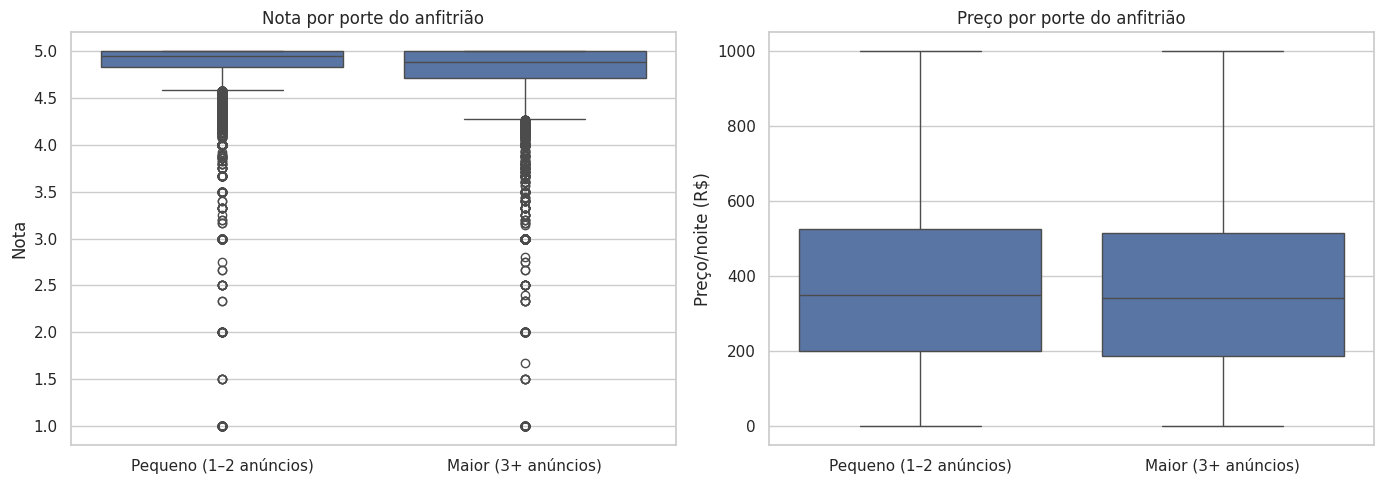

In [7]:
if {'porte_anfitriao', 'review_scores_rating'}.issubset(analysis.columns):
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    sns.boxplot(data=analysis, x='porte_anfitriao', y='review_scores_rating', ax=ax[0])
    ax[0].set_title('Nota por porte do anfitrião'); ax[0].set_xlabel(''); ax[0].set_ylabel('Nota')
    if 'price_brl' in analysis.columns:
        sns.boxplot(data=analysis, x='porte_anfitriao', y='price_brl', showfliers=False, ax=ax[1])
        ax[1].set_title('Preço por porte do anfitrião'); ax[1].set_xlabel(''); ax[1].set_ylabel('Preço/noite (R$)')
    plt.tight_layout(); plt.show()

## 6. Avaliação e recomendações

- **Preço:** comparar o anúncio com a mediana do mesmo bairro, tipo e capacidade; testar faixas e descontos.
- **Confiança:** melhorar fotos, descrição, regras e experiência para elevar nota e reviews.
- **Disponibilidade:** revisar calendário e restrições; anunciar datas indisponíveis desperdiça mídia.
- **Segmentação:** combinar bairro, capacidade, tipo de imóvel e faixa de preço com o público da campanha.
- **Pequenos anfitriões:** usar a comparação por porte para encontrar vantagens reais, sem assumir que escala significa melhor desempenho.
- **Medição:** integrar Ads, Analytics e CRM para acompanhar impressão → clique → visita → reserva → receita.

## 7. Impacto social, inovação e implantação

A análise apoia pequenos anfitriões com recomendações de baixo custo, como ajuste de preço, melhoria das fotos, descrição mais clara e calendário atualizado. Isso transforma dados públicos em orientação prática sem prometer resultados que a base não consegue medir.

Para implantar, recomenda-se um painel mensal por anúncio, acompanhamento antes/depois e integração com dados de campanhas e reservas. Testes de preço, foto ou descrição devem ser avaliados por reservas e receita, não apenas por nota ou reviews.

## 8. Considerações finais

O projeto identifica padrões da oferta e compara pequenos e maiores anfitriões. Porém, o CSV não possui impressões, cliques, investimento, CPC, CTR ou reservas atribuídas a campanhas. Reviews, notas e disponibilidade são proxies e não provam conversão de tráfego pago.

A conclusão deve ser preenchida após executar as células: pequenos anfitriões são competitivos nas dimensões em que suas medianas se aproximarem ou superarem as do grupo maior, controlando por bairro e tipo de acomodação.